# COMP 551 Assignment 3

## Task 1: Acquire the data

In [ ]:
!pip install torchvision
!pip install torchinfo

In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

# CNN imports
import time
from torchvision import models
from torchinfo import summary
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F


### **Step 1: Load Dataset**

In [ ]:
# dataset objects: .data = all images (N, 28, 28), uint8 0-255; .targets = labels
# dataset[i] applies ToTensor -> image [1, 28, 28], float 0-1
train_dataset_raw = datasets.FashionMNIST(root='./data', train=True, download=True,
                                      transform=transforms.ToTensor())
test_dataset_raw = datasets.FashionMNIST(root='./data', train=False, download=True,
                                      transform=transforms.ToTensor())

# Create transform pipeline for data augmentation in Q5
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()
])

# data set object transformed for data augmentation in Q5
train_dataset_aug = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)

In [ ]:
image, label = train_dataset_raw[0]

# assign input dimension width
I = train_dataset_raw.data.shape[1]

print(type(image))
print(image.shape)
print(image.dtype)
print(image.device)
print(f"\nTrain partition: {train_dataset_raw.data.shape} {len(train_dataset_raw)} images")
print(f"Test partition: {test_dataset_raw.data.shape} {len(test_dataset_raw)} images")
print(f'Input dimension: {I}')

<class 'torch.Tensor'>
torch.Size([1, 28, 28])
torch.float32
cpu

Train partition: torch.Size([60000, 28, 28]) 60000 images
Test partition: torch.Size([10000, 28, 28]) 10000 images
Input dimension: 28


### **Step 2: Split Training Partition**

In [ ]:
""" Split the default training partition (60k images)
into training and validation partitions """

from torch.utils.data import Subset

split_ratio = 0.8
split_point = int(split_ratio * len(train_dataset_raw))

rng = np.random.default_rng(2026)
indices = np.arange(len(train_dataset_raw))
rng.shuffle(indices)
train_indices = indices[:split_point]
val_indices = indices[split_point:]

train_set = Subset(train_dataset_raw, train_indices)
val_set   = Subset(train_dataset_raw, val_indices)

print(f"Train size: {len(train_set)}")
print(f"Validation size: {len(val_set)}")

Train size: 48000
Validation size: 12000


### **Step 3: Flatten Dataset**

In [ ]:
# bring subsets into numpy (raw images)
X_train = train_dataset_raw.data.numpy()[train_indices]
X_val   = train_dataset_raw.data.numpy()[val_indices]
X_test  = test_dataset_raw.data.numpy()

# make a subset of augmented images that are fetched by image
train_set_aug = Subset(train_dataset_aug, train_indices)
train_loader_aug = DataLoader(train_set_aug, batch_size=len(train_set_aug), shuffle=False)

#run through train_loader and perform transforms
torch.manual_seed(2026)
xb, yb = next(iter(train_loader_aug))
xb = xb.numpy()


print(f'X_train: {X_train.shape}')
print(f'X_train_aug: {xb.shape}')
print(f'X_val: {X_val.shape}')
print(f'X_test: {X_test.shape}')

# labels
y_train = train_dataset_raw.targets.numpy()[train_indices]
y_val   = train_dataset_raw.targets.numpy()[val_indices]
y_test  = test_dataset_raw.targets.numpy()

# flatten [vectorize 28*28 = 784]
x_train = X_train.reshape(-1, 784).astype(np.float32) # convert to float
x_train_aug = xb.reshape(-1, 784).astype(np.float32)*255 # scale from 0 to 1 --> 0 to 255
x_val = X_val.reshape(-1, 784).astype(np.float32)
x_test = X_test.reshape(-1, 784).astype(np.float32)

print(f'\nx_train: dtype {x_train.dtype}, min {x_train.min():.3f}, max {x_train.max():.3f}, mean {x_train.mean():.3f}')
print(f'x_train_aug: dtype {x_train_aug.dtype}, min {x_train_aug.min():.3f}, max {x_train_aug.max():.3f}, mean {x_train_aug.mean():.3f}')

print(f'\nCheck Flattened Shape:')
print(f'x_train: {x_train.shape}')
print(f'x_train_aug: {x_train_aug.shape}')
print(f'x_val: {x_val.shape}')
print(f'x_test: {x_test.shape}')

# keep unnormalized copies for Q4
x_train_raw, x_val_raw, x_test_raw = x_train.copy(), x_val.copy(), x_test.copy()
x_train_aug_raw = x_train_aug.copy()


X_train: (48000, 28, 28)
X_train_aug: (48000, 1, 28, 28)
X_val: (12000, 28, 28)
X_test: (10000, 28, 28)

x_train: dtype float32, min 0.000, max 255.000, mean 72.877
x_train_aug: dtype float32, min 0.000, max 255.000, mean 73.103

Check Flattened Shape:
x_train: (48000, 784)
x_train_aug: (48000, 784)
x_val: (12000, 784)
x_test: (10000, 784)


### **Step 4: Normalize Dataset**

In [ ]:
# normalization statistics from the training split only (not validation)
# this method based on numpy simplicity in the CS231n data processing reference

mean = x_train_raw.mean()
std = x_train_raw.std()
print(f'train mean: {mean:.3f}, train std: {std:.3f}')

# apply the same mean and std to all three sets
x_train = (x_train_raw - mean) / std
x_train_aug = (x_train_aug_raw - mean) / std
x_val   = (x_val_raw - mean) / std
x_test  = (x_test_raw - mean) / std

print(f'\ntrain: mean {x_train.mean():.3f}, std {x_train.std():.3f}')
print(f'train (augmented): mean{x_train_aug.mean():.3f}, std {x_train_aug.std():.3f}')
print(f'val:   mean {x_val.mean():.3f}, std {x_val.std():.3f}')
print(f'test:  mean {x_test.mean():.3f}, std {x_test.std():.3f}')


train mean: 72.877, train std: 90.006

train: mean 0.000, std 1.000
train (augmented): mean0.003, std 0.981
val:   mean 0.003, std 1.001
test:  mean 0.003, std 0.999


In [ ]:
# Concatenate clean + augmented data set for Q5
x_train_augExpand = np.concatenate((x_train, x_train_aug), axis=0)
y_train_augExpand = np.concatenate((y_train, y_train), axis=0)

print(f'x_train_augExpand: {x_train_augExpand.shape}')
print(f'y_train_augExpand: {y_train_augExpand.shape}')

x_train_augExpand: (96000, 784)
y_train_augExpand: (96000,)


### **Step 5: Exploratory Data Analysis**

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

#### 1. Dataset structure

In [ ]:
for root, dirs, files in os.walk('./data/FashionMNIST'):

    level = root.replace('./data/FashionMNIST', "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:]:
        print(f"{indent}    {file}")

print(train_dataset_raw)
print("Images shape:", train_dataset_raw.data.shape)
print("Labels shape:", train_dataset_raw.targets.shape)
class_names = train_dataset_raw.classes

print("Number of classes:", len(class_names))
for class_id, class_name in enumerate(class_names):
    print(class_id, class_name)


FashionMNIST/
    raw/
        train-labels-idx1-ubyte
        train-images-idx3-ubyte
        t10k-images-idx3-ubyte
        t10k-images-idx3-ubyte.gz
        t10k-labels-idx1-ubyte.gz
        t10k-labels-idx1-ubyte
        train-labels-idx1-ubyte.gz
        train-images-idx3-ubyte.gz
Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Images shape: torch.Size([60000, 28, 28])
Labels shape: torch.Size([60000])
Number of classes: 10
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot


#### 2. Class Distribution - images per category

         Class  Train  Validation  Test  Total
0  T-shirt/top   4755        1245  1000   7000
1      Trouser   4852        1148  1000   7000
2     Pullover   4803        1197  1000   7000
3        Dress   4810        1190  1000   7000
4         Coat   4775        1225  1000   7000
5       Sandal   4819        1181  1000   7000
6        Shirt   4791        1209  1000   7000
7      Sneaker   4765        1235  1000   7000
8          Bag   4834        1166  1000   7000
9   Ankle boot   4796        1204  1000   7000


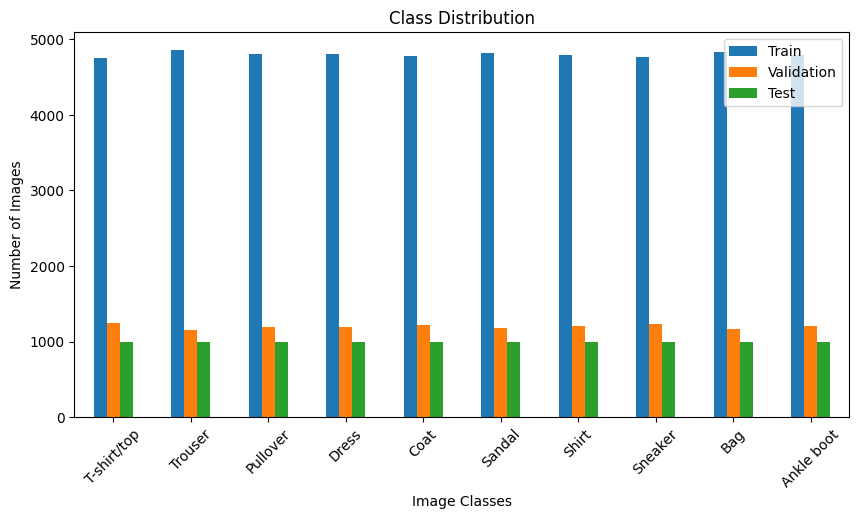

In [ ]:
class_names = train_dataset_raw.classes

splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

class_counts = {"Class": class_names}

for split_name, labels in splits.items():
    class_counts[split_name] = np.bincount(labels, minlength=10)

class_df = pd.DataFrame(class_counts)
class_df["Total"] = class_df[["Train", "Validation", "Test"]].sum(axis=1)

print(class_df)

class_df.plot(
    kind="bar",
    x="Class",
    y=["Train", "Validation", "Test"],
    figsize=(10, 5)
)

plt.title("Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

#### 3. Random raw images

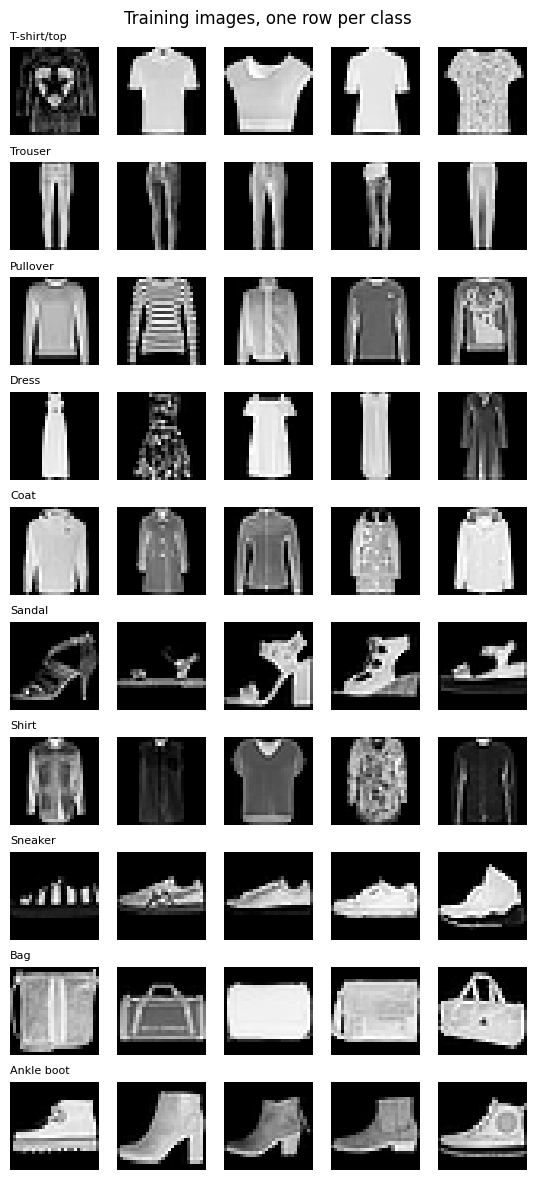

In [ ]:
n_show = 5
fig, axes = plt.subplots(10, n_show, figsize=(n_show * 1.1, 10 * 1.2))
for c in range(10):
    examples = np.where(y_train == c)[0][:n_show]
    for j, i in enumerate(examples):
        axes[c, j].imshow(x_train[i].reshape(28, 28), cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(class_names[c], fontsize=8, loc='left')
plt.suptitle('Training images, one row per class')
plt.tight_layout()
plt.show()

#### 4.Pixel distribution — mean, std, intensity

raw train pixels: mean 72.88, std 90.01


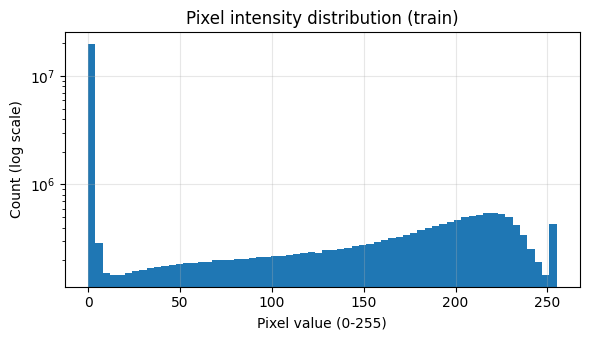

In [ ]:
x_all_train = train_dataset_raw.data.numpy()
y_all_train = train_dataset_raw.targets.numpy()
x_all_test  = test_dataset_raw.data.numpy()
y_all_test  = test_dataset_raw.targets.numpy()

X_train_hist = x_all_train[train_indices]   # same split as the rest of the notebook

print(f'raw train pixels: mean {X_train_hist.mean():.2f}, std {X_train_hist.std():.2f}')

plt.figure(figsize=(6, 3.5))
plt.hist(X_train_hist.ravel(), bins=64, log=True)
plt.xlabel('Pixel value (0-255)')
plt.ylabel('Count (log scale)')
plt.title('Pixel intensity distribution (train)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 5. Data integrity -- corrupted images


In [ ]:
invalid = []
for i in range(len(train_dataset_raw)):              # reading every image like during training
    try:
        img, lable = train_dataset_raw[i]
    except Exception as e:
        invalid.append(("train", i))
for i in range(len(test_dataset_raw)):
    try:
        img, lable = test_dataset_raw[i]
    except Exception as e:
        invalid.append(('test', i))
print(f"Invalid images: {len(invalid)}")

for name, x, y in [('train partition', x_all_train, y_all_train), ('test partition', x_all_test, y_test)]:
    print(f"\n{name}:")
    print(f"  all images 28x28:        {x.shape[1:] == (28, 28)}")
    print(f"  pixel range:             [{x.min()}, {x.max()}]")
    print(f"  NaN values:              {np.isnan(x.astype(float)).sum()}")
    print(f"  labels in [0,9]:          {set(np.unique(y)) <= set(range(10))}")
    print(f"  completely blank images: {(x.reshape(len(x), -1).max(axis=1) == 0).sum()}")

Invalid images: 0

train partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0

test partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0


#### 6. Data leakage

In [ ]:
# 6.1 image index in both training and validation
print(f"Indices shared by train and validation: {len(set(train_indices) & set(val_indices))}")

Indices shared by train and validation: 0


## Task 2: Implement a Multilayer Perceptron

Our model is an MLP with $L-1$ hidden layers and a softmax output layer:

$$
z_0 = x, \qquad
a_l = z_{l-1} W_l + b_l, \qquad
z_l = h(a_l) \quad \text{for } l = 1, \dots, L-1
$$

$$
\hat{y} = \operatorname{softmax}(a_L), \qquad a_L = z_{L-1} W_L + b_L
$$

$x$ is the flattened image (784 pixels), $h$ is the hidden activation function, $W_l$ and $b_l$ are the weights and bias for layer $l$, and $\hat{y}$ is the output probability of each of the 10 categories (softmax since it's multi-class).


An MLP is composed of three types of layers:

(1) an input layer -> flattened 784 pixels

(2) hidden layers -> every layer: $z = h(Wx+b)$ (linear transformation -> activation function)

    - Activation Function: ReLU, Tanh, Leaky-ReLU

(3) an output layer -> the probability of 10 categories $\left ( \operatorname{softmax}(u)_k = \frac{\exp(u_k)}{\sum_j \exp(u_j)} \right )$

(4)Loss:


$$L = -\frac{1}{N}\sum_{n}\sum_{k} y_{nk}\log \hat{y}_{nk}, \quad \hat{y} = \text{softmax}(a)$$

**Forward Pass:**

x --W1--> a1 --h--> z1 --W2--> a2 --h--> z2..... --Wl--> al --softmax--> yh --> L

#### Gradient

- Taking the derivative with respect to the last layer's pre-activation `a`:

$$\frac{\partial L}{\partial a} = \frac{\hat{y} - y}{N}$$

- $a = zW + b$

$$\frac{\partial L}{\partial w} = z^{T}  \frac{\partial L}{\partial a}$$
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial a} w^{T}$$

*Chain Rule*

For $ z = h(a_{l-1})$

$$\frac{\partial L}{\partial a_{l-1}} =  h'(a_{l-1}) \odot \frac{\partial L}{\partial z}$$

- h(): activation function

Implementation should include

    - backpropagation

    - mini-batch gradient descent algorithm

- Leaky-ReLU slope γ is fixed at 0.01 here (making γ learnable would give PReLU, a possible extension)

- Weight Initialization

| Method                | Common application | Main idea                                      |
|-----------------------|--------------------|------------------------------------------------|
| Zero initialization   | Biases             | Initialize biases to zero                      |
| Random initialization | General concept    | Start weights with random values               |
| Xavier (Glorot)       | Tanh, sigmoid      | $\operatorname{Var}(W)=\frac{2}{n_{in}+n_{out}}$ |
| He (Kaiming)          | ReLU, Leaky ReLU   | $\operatorname{Var}(W)=\frac{2}{n_{in}}$         |


In [ ]:
#Activation Function
relu = lambda a: np.maximum(0, a)
relu_grad = lambda a: (a > 0).astype(float)

tanh = lambda a: np.tanh(a)
tanh_grad = lambda a: 1 - np.tanh(a) ** 2

leaky_relu = lambda a: np.maximum(0, a) + 0.01 * np.minimum(0, a)
leaky_relu_grad = lambda a: np.where(a > 0, 1., 0.01)

activations = {'relu': (relu, relu_grad),
               'tanh': (tanh, tanh_grad),
               'leaky_relu': (leaky_relu, leaky_relu_grad)}

In [ ]:
#The constructor for the class should take as input
# the activation function (e.g., ReLU),
# the number of hidden layers (e.g., 2)
# the number of units in the hidden layers (e.g., [64, 64])
# initialize the weights and biases (with an initializer of your choice)
# as well as other important properties of the MLP.
def one_hot(y, C):
    Y = np.zeros((len(y), C))
    Y[np.arange(len(y)), y] = 1                 # e.g. label 3 -> [0,0,0,1,0,0,0,0,0,0]
    return Y

def softmax(a):
    a = a - np.max(a, axis=1, keepdims=True)
    e = np.exp(a)
    return e / np.sum(e, axis=1, keepdims=True)

class MLP:

    def __init__(self, activation, n_hidden_layers, hidden_units, n_input , n_output, init = "default", L1 = 0, L2 = 0):
        '''
        Initialize a multilayer perceptron with a softmax output layer.

        Architecture: x -> [W1,b1] -> h -> [W2,b2] -> h -> ... -> [WL,bL] -> softmax -> yh

        Parameters:
        activation: hidden activation, 'relu', 'tanh' or 'leaky_relu'
        n_hidden_layers: number of hidden layers
        hidden_units: list with the number of units of each hidden layer
        n_input: number of input features D
        n_output: number of classes C
        init: ReLU, Leaky ReLU, Tanh or default for 0.01
        '''
        self.activation = activation
        self.n_hidden_layers = n_hidden_layers
        self.hidden_units = hidden_units
        self.h, self.h_grad = activations[activation]
        self.input_dim = n_input
        self.output_dim = n_output
        self.init = init
        self.L1 = L1
        self.L2 = L2

        self.layer_sizes = [n_input] +list(hidden_units)+[n_output]
        # Store parameters as a list for the optimizer
        self.params = [] # [W1,b1,W2,b2,...,Wl,bl]

        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            if init == 'relu' or init == "leaky_relu":
                scale = np.sqrt(2 / n_in)
            elif init == 'tanh':
                scale = np.sqrt(2 / (n_in + n_out))
            elif init == 'default':
                scale = .01
            else:
                raise ValueError(f"Unknown init: {init}")
            W = np.random.randn(n_in, n_out) * scale  # W_{i} (n_in, n_out)
            b = np.zeros(n_out)                         # (n_out,)

            self.params.extend([W, b])

    def forward(self, x, params):
        """
        Forward pass through the network.

        Parameters:
        x: input features, shape (N, D)
        params: [W1,b1,W2,b2,...,Wl,bl]
        Returns:
        out: predicted probabilities, shape (N, 10)

        """
        L = len(params) // 2 # number of layers [W1,b1,W2,b2,...,Wl,bl]
        z = x
        h_u, p_a = [x],[]
        for l in range(L):
            W, b = params[2*l], params[2*l+1]
            a = np.dot(z, W) + b # pre-activation
            p_a.append(a)
            if l < L - 1:   # without output layer, all hidden layers go through activation function
                z = self.h(a) # after activation
                h_u.append(z)     # h_u[l] the input of l-th layer
        yh = softmax(a)

        return yh, h_u, p_a

    def gradient(self, x, y, params):
        """
        Compute gradients for both layers using backpropagation.

        Parameters:
        x: input features, shape (N, D)
        y: true labels, shape (N,)
        params: list [w1, b1... wL, bL]

        Returns:
        params: list [dw1, db1... dwL, dbL] containing gradients for W and b
        """
        N = x.shape[0]
        L = len(params) // 2
        yh, h_u, p_a = self.forward(x, params)
        # Store gradients
        dparams = [None] * len(params) #[dW1, db1, dW2, db2, ...]

        da = (yh - one_hot(y, yh.shape[1])) / N # the derivative with respect to the last layer's pre-activation

        for l in reversed(range(L)):
             W = params[2 * l]
             dW = np.dot(h_u[l].T, da)
             dW = dW + self.L1 * np.sign(W) + self.L2 * W     ## changes: regularization
             db = np.sum(da, axis=0)
             dparams[2 * l], dparams[2 * l + 1] = dW, db
             if l > 0:
                dz = np.dot(da, W.T)
                da = dz * self.h_grad(p_a[l - 1])

        return dparams


    def fit(self, x, y, optimizer):

        self.params = optimizer.run(self.gradient, x, y, self.params)
        return self

    def predict(self, x):
        yh, _, _ = self.forward(x, self.params)
        return np.argmax(yh, axis=1)

def evaluate_acc(y, yh):
    return np.mean(y == yh)



### Mini-batch gradient descent (batch_size config)

In [ ]:
class GradientDescent:

    # batch_size: N = full-batch GD, 64 = mini-batch (default), 1 = SGD
    def __init__(self, learning_rate, epochs = 10, batch_size = 64):

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size

    def run(self, gradient_fn, x, y, params):

        N = x.shape[0]
        for epoch in range(self.epochs):
            # shuffle the training data every epoch
            order = np.random.permutation(N)

            # select a batch of `batch_size` samples each time
            for i in range(0, N, self.batch_size):
                batch = order[i : i+self.batch_size]
                grad = gradient_fn(x[batch], y[batch], params)
                for p in range(len(params)):
                    params[p] -= self.learning_rate * grad[p]


            print(f"Epoch {epoch + 1}/{self.epochs} done")
        return params

In [ ]:
np.random.seed(2026) # reset global RNG: same initial weights & GradientDescent shuffling, so runs are reproducible
model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
            n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model.fit(x_train, y_train, optimizer)

print(evaluate_acc(y_train, model.predict(x_train)))

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
0.9313541666666667


## Task 3: Run the experiments and report

1.
- an MLP with no hidden layers, i.e., it directly maps the inputs to outputs; (784 -> 10 -> softmax)
- an MLP with a single hidden layer having 256 units and ReLU activations; (784 -> 256 (ReLU)-> 10 -> softmax)
- an MLP with 2 hidden layers each having 256 units with ReLU activations. (784 -> 256 (ReLU) -> 256 (ReLU) ->10 -> softmax)

Have a softmax layer at the end.
After training, compare the test accuracy of these three models on the FashionMNIST dataset.
Comment on how non-linearity and network depth affects the accuracy. Are the results that you obtain expected?

### Hyperparameter selection

#### 1. Learning rate

In [ ]:
# Learning-rate sweep on the 2-hidden-layer ReLU MLP (selected by VALIDATION accuracy)
lr_rows = []
for lr in [0.005, 0.01, 0.05, 0.1, 0.2]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train, y_train, GradientDescent(learning_rate=lr, epochs=10, batch_size=64))
    lr_rows.append({'learning rate': lr,
                    'train acc': evaluate_acc(y_train, model.predict(x_train)),
                    'val acc':   evaluate_acc(y_val,   model.predict(x_val))})

pd.DataFrame(lr_rows).round(3)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,learning rate,train acc,val acc
0,0.005,0.886,0.873
1,0.010,0.902,0.879
2,0.050,0.931,0.892
3,0.100,0.935,0.888
4,0.200,0.930,0.888


#### 2. Batch Size

In [ ]:
# Batch-size sweep
bs_rows = []
for bs in [32, 64, 128, 256]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=bs))
    bs_rows.append({'batch size': bs,
                    'epoch': int(np.ceil(len(x_train) / bs)),
                    'train acc': evaluate_acc(y_train, model.predict(x_train)),
                    'val acc':   evaluate_acc(y_val,   model.predict(x_val))})

pd.DataFrame(bs_rows).round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,batch size,epoch,train acc,val acc
0,32,1500,0.9380,0.8896
1,64,750,0.9314,0.8922
2,128,375,0.9200,0.8862
3,256,188,0.8960,0.8750


- leaning rate 0.05 is good
- batch size 64 is good.

###3.1

In [ ]:
# 1: MLP with no hidden layer
np.random.seed(2026)
model_0 = MLP(activation='relu', n_hidden_layers=0, hidden_units=[],
              n_input=784, n_output=10, init='relu') # keep the initial the same
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_0.fit(x_train, y_train, optimizer)

train_acc_0 = evaluate_acc(y_train, model_0.predict(x_train))
test_acc_0  = evaluate_acc(y_test,  model_0.predict(x_test))

# 2: MLP with 1 hidden layer (256 units, ReLU)
model_1 = MLP(activation='relu', n_hidden_layers=1, hidden_units=[256],
              n_input=784, n_output=10, init='relu') # keep the initial the same
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_1.fit(x_train, y_train, optimizer)

train_acc_1 = evaluate_acc(y_train, model_1.predict(x_train))
test_acc_1  = evaluate_acc(y_test,  model_1.predict(x_test))

# 3: MLP with 2 hidden layers (256 units each, ReLU)
model_2 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
              n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_2.fit(x_train, y_train, optimizer)

train_acc_2 = evaluate_acc(y_train, model_2.predict(x_train))
test_acc_2  = evaluate_acc(y_test,  model_2.predict(x_test))
# result
print(f'No hidden layer -> train accuracy: {train_acc_0:.4f}, test accuracy: {test_acc_0:.4f}')
print(f'1 hidden layer -> train accuracy: {train_acc_1:.4f}, test accuracy: {test_acc_1:.4f}')
print(f'2 hidden layers -> train accuracy: {train_acc_2:.4f}, test accuracy: {test_acc_2:.4f}')


Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
No hidden layer -> train accuracy: 0.8620, test accuracy: 0.8364
1 hidden layer -> train accuracy: 0.9221, test accuracy: 0.8779
2 hidden layers -> train accuracy: 0.9382, test accuracy: 0.8802


In [ ]:
q1_table = pd.DataFrame({
    'model':     ['No hidden layer', '1 hidden layer (256)', '2 hidden layers (256, 256)'],
    'train accuracy': [train_acc_0, train_acc_1, train_acc_2],
    'test accuracy':  [test_acc_0,  test_acc_1,  test_acc_2],
})
q1_table['train - test'] = q1_table['train accuracy'] - q1_table['test accuracy']
q1_table.round(4)

# model_0 to model_1 shows the effect of non-linearity, train and test accuracy is not high, underfitting
# model_1 to model_2 shows the effect of network depth affects the accuracy

,model,train accuracy,test accuracy,train - test
0,No hidden layer,0.8620,0.8364,0.0256
1,1 hidden layer (256),0.9221,0.8779,0.0442
2,"2 hidden layers (256, 256)",0.9382,0.8802,0.0580


###3.2

Take the one with 2 hidden layers, change activation:
1) tanh and
2) Leaky-ReLU.

After training these two models compare their test accuracies with model having ReLU activations.

Comment on the performances of these models: which one is better and why? Are certain activations better than others? If the results are not as you expected, what could be the reason?

In [ ]:
# 2 hidden layers with tanh activation
np.random.seed(2026)
model_tanh = MLP(activation='tanh', n_hidden_layers=2, hidden_units=[256, 256],
                 n_input=784, n_output=10, init='tanh')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_tanh.fit(x_train, y_train, optimizer)

train_acc_tanh = evaluate_acc(y_train, model_tanh.predict(x_train))
test_acc_tanh  = evaluate_acc(y_test,  model_tanh.predict(x_test))
print(f'tanh -> train accuracy: {train_acc_tanh:.4f}, valid accuracy: {test_acc_tanh:.4f}')

# Q2-2: 2 hidden layers with Leaky-ReLU activation
model_leaky = MLP(activation='leaky_relu', n_hidden_layers=2, hidden_units=[256, 256],
                  n_input=784, n_output=10, init='leaky_relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_leaky.fit(x_train, y_train, optimizer)

train_acc_leaky = evaluate_acc(y_train, model_leaky.predict(x_train))
test_acc_leaky  = evaluate_acc(y_test,  model_leaky.predict(x_test))
print(f'Leaky-ReLU -> train accuracy: {train_acc_leaky:.4f}, test accuracy: {test_acc_leaky:.4f}')

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
tanh -> train accuracy: 0.9278, valid accuracy: 0.8793
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Leaky-ReLU -> train accuracy: 0.9400, test accuracy: 0.8848


In [ ]:
q2_table = pd.DataFrame({
    'activation': ['ReLU', 'Tanh', 'Leaky-ReLU'],
    'train accuracy':  [train_acc_2, train_acc_tanh, train_acc_leaky],
    'test accuracy':   [test_acc_2,  test_acc_tanh,  test_acc_leaky],
})
q2_table['train - test'] = q2_table['train accuracy'] - q2_table['test accuracy']
q2_table.round(4)

,activation,train accuracy,test accuracy,train - test
0,ReLU,0.9382,0.8802,0.0580
1,Tanh,0.9278,0.8793,0.0485
2,Leaky-ReLU,0.9400,0.8848,0.0552


In [ ]:
# Dead units: hidden units whose pre-activation a <= 0 for validation sample
dead_rows = []
for name, m in [('ReLU', model_2), ('Leaky-ReLU', model_leaky)]:
    _, _, p_a = m.forward(x_val, m.params)
    for l in range(2):                              # the 2 hidden layers
        a = p_a[l]
        dead_rows.append({'activation': name,
                          'layer': l + 1,
                          'dead units': np.mean(np.all(a <= 0, axis=0))})

pd.DataFrame(dead_rows)

,activation,layer,dead units
0,ReLU,1,0.0
1,ReLU,2,0.0
2,Leaky-ReLU,1,0.0
3,Leaky-ReLU,2,0.0


In [ ]:
# Repeat with 5 seeds to check
seed_rows = []
for act in ['relu', 'tanh', 'leaky_relu']:
    for seed in [2024, 2025, 2026, 2027, 2028]:
        np.random.seed(seed)
        m = MLP(activation=act, n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init=act)
        m.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
        seed_rows.append({'activation': act, 'seed': seed,
                          'train accuracy': evaluate_acc(y_train, m.predict(x_train)),
                          'test accuracy':  evaluate_acc(y_test,  m.predict(x_test))})

seed_df = pd.DataFrame(seed_rows)
seed_df.groupby('activation')[['train accuracy', 'test accuracy']].agg(['mean', 'std']).round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Ep

train accuracy         test accuracy        
                     mean     std          mean     std
activation                                             
leaky_relu         0.9333  0.0032        0.8784  0.0021
relu               0.9348  0.0022        0.8770  0.0018
tanh               0.9259  0.0030        0.8789  0.0022

###3.3

independently add L1 and L2 regularization to the network and train the MLP in this way.
- $$\text{L1:}\quad J = L + \lambda_1 \sum |W| \qquad \text{L2:}\quad J = L + \frac{\lambda_2}{2} \sum W^2$$
- $$\qquad \frac{\partial J}{\partial W} = \frac{\partial L_{CE}}{\partial W} + \lambda_1\,\text{sign}(W) \quad \frac{\partial J}{\partial W} = \frac{\partial L_{CE}}{\partial W} + \lambda_2 W$$

In [ ]:
L1_rows = []
for lam in [0, 1e-6, 1e-5, 1e-4, 1e-3]:
    np.random.seed(2026)
    model_l1 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L1=lam)
    model_l1.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    L1_rows.append({'lambda_1': lam,
                    'train accuracy': evaluate_acc(y_train, model_l1.predict(x_train)),
                    'val accuracy':   evaluate_acc(y_val,   model_l1.predict(x_val)),
                    'test accuracy':  evaluate_acc(y_test,  model_l1.predict(x_test))})

pd.DataFrame(L1_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,lambda_1,train accuracy,val accuracy,test accuracy
0,0.000000,0.931354,0.892250,0.8770
1,0.000001,0.931500,0.891500,0.8785
2,0.000010,0.929896,0.889583,0.8787
3,0.000100,0.911000,0.886750,0.8754
4,0.001000,0.853375,0.848250,0.8396


λ1=0 val accuracy is highest -- regularization did not help

In [125]:
L2_rows = []
for lam in [0, 1e-6, 1e-5, 1e-4, 1e-3]:
    np.random.seed(2026)
    model_l2 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=lam)
    model_l2.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    L2_rows.append({'lambda_2': lam,
                    'train accuracy': evaluate_acc(y_train, model_l2.predict(x_train)),
                    'val accuracy':   evaluate_acc(y_val,   model_l2.predict(x_val)),
                    'test accuracy':  evaluate_acc(y_test,  model_l2.predict(x_test))})

pd.DataFrame(L2_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,lambda_2,train accuracy,val accuracy,test accuracy
0,0.000000,0.931354,0.892250,0.8770
1,0.000001,0.931125,0.889250,0.8772
2,0.000010,0.930375,0.891000,0.8766
3,0.000100,0.930833,0.893167,0.8809
4,0.001000,0.922625,0.890417,0.8785


λ2=0.0001 regularization helped but nominally +0.0039 accuracy

###3.4

In [106]:
# Q4: trained on unnormalized pixels
np.random.seed(2026)
model_raw = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
model_raw.fit(x_train_raw, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))

print(f'train accuracy: {evaluate_acc(y_train, model_raw.predict(x_train_raw)):.4f}')
print(f'validation accuracy:   {evaluate_acc(y_val,   model_raw.predict(x_val_raw)):.4f}')
print(f'test accuracy:  {evaluate_acc(y_test,  model_raw.predict(x_test_raw)):.4f}')

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
train accuracy: 0.1001
validation accuracy:   0.0998
test accuracy:  0.1000


In [107]:
# Check the weights and the dead units after training
_, _, p_a = model_raw.forward(x_val_raw, model_raw.params)
print(f'max |W1|: {np.abs(model_raw.params[0]).max():.3g}')
print(f'dead units in layer 1: {np.mean(np.all(p_a[0] <= 0, axis=0)):.4f}')
print(f'max |W2|: {np.abs(model_raw.params[2]).max():.3g}')
print(f'dead units in layer 2: {np.mean(np.all(p_a[1] <= 0, axis=0)):.4f}')


max |W1|: 1.1e+14
dead units in layer 1: 0.9922
max |W2|: 6.6e+20
dead units in layer 2: 0.9844


In [108]:
# Is it only the learning rate? Re-tune lr for raw inputs (selected by validation)
raw_rows = []
for lr in [1e-3, 5e-4, 1e-4, 5e-5, 1e-5]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train_raw, y_train, GradientDescent(learning_rate=lr, epochs=10, batch_size=64))
    raw_rows.append({'learning rate': lr,
                     'train acc': evaluate_acc(y_train, model.predict(x_train_raw)),
                     'val acc':   evaluate_acc(y_val,   model.predict(x_val_raw))})

pd.DataFrame(raw_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,learning rate,train acc,val acc
0,0.00100,0.707000,0.699583
1,0.00050,0.849375,0.819000
2,0.00010,0.844167,0.817917
3,0.00005,0.830250,0.809583
4,0.00001,0.794458,0.785750


###3.5

*Retrain the MLP from Q3 on a version of FashionMNIST using data augmentation.*

In [109]:
# Q5: Retrain MLP Q3 (2 layer, 256 units, ReLU activation, l2 = 0.0001) on augmented data

import time

np.random.seed(2026)
# L2 from Q3 optimization
model_aug = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=0.0001)
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_aug.fit(x_train_augExpand, y_train_augExpand, optimizer)

train_acc_aug = evaluate_acc(y_train_augExpand, model_aug.predict(x_train_augExpand))
val_acc_aug   = evaluate_acc(y_val,   model_aug.predict(x_val))
test_acc_aug  = evaluate_acc(y_test,  model_aug.predict(x_test))

# Q3 model: clean data - time comparison
np.random.seed(2026)
model_q3 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
               n_input=784, n_output=10, init='relu', L2=0.0001)
t0 = time.time()
model_q3.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
time_q3 = time.time() - t0

# Q5 model: clean + augmented data - time comparison
np.random.seed(2026)
model_aug = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=0.0001)
t0 = time.time()
model_aug.fit(x_train_augExpand, y_train_augExpand, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
time_aug = time.time() - t0

#results
q3_l2 = pd.DataFrame(L2_rows)
q3 = q3_l2[q3_l2['lambda_2'] == 1e-4].iloc[0]

pd.DataFrame([
    {'model': 'Q3: L2=0.0001, clean data',
     'train data size': len(x_train),
     'train acc': evaluate_acc(y_train, model_q3.predict(x_train)),
     'val acc':   evaluate_acc(y_val,   model_q3.predict(x_val)),
     'test acc':  evaluate_acc(y_test,  model_q3.predict(x_test)),
     'train time (s)': time_q3},
    {'model': 'Q5: L2=0.0001, clean + augmented',
     'train data size': len(x_train_augExpand),
     'train acc': evaluate_acc(y_train_augExpand, model_aug.predict(x_train_augExpand)),
     'val acc':   evaluate_acc(y_val,   model_aug.predict(x_val)),
     'test acc':  evaluate_acc(y_test,  model_aug.predict(x_test)),
     'train time (s)': time_aug},
]).set_index('model').round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,train data size,train acc,val acc,test acc,train time (s)
model,,,,,
"Q3: L2=0.0001, clean data",48000,0.9308,0.8932,0.8809,51.6276
"Q5: L2=0.0001, clean + augmented",96000,0.9271,0.8888,0.8810,111.4502


augmenting data doesn't improve validation accuracy for the L2 regularized MLP in Q3

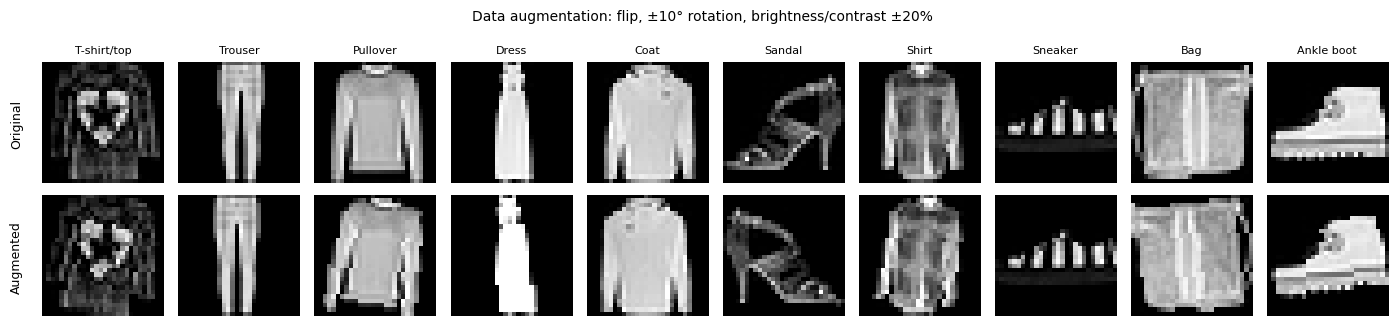

In [110]:
# Q5: original vs augmented examples, one per class
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for c in range(10):
    i = np.where(y_train == c)[0][0]          # first training image of class c
    axes[0, c].imshow(X_train[i], cmap='gray')
    axes[1, c].imshow(xb[i, 0], cmap='gray')  # same image after augmentation
    axes[0, c].set_title(class_names[c], fontsize=8)
    axes[0, c].axis('off')
    axes[1, c].axis('off')

axes[0, 0].text(-8, 14, 'Original',  rotation=90, va='center', fontsize=9)
axes[1, 0].text(-8, 14, 'Augmented', rotation=90, va='center', fontsize=9)
plt.suptitle('Data augmentation: flip, ±10° rotation, brightness/contrast ±20%', fontsize=10)
plt.tight_layout()
plt.show()

The testing accuracy is basically the same in Q5 as Q3, 0.8809 vs 0.8810, and validation went down a little from 0.8932 to 0.8888, which is small enough to be seed noise.

###3.6

*Create a CNN class*

In [111]:
# Q6 create CNN with 2 convolutional layers, one fully connected (FC) hidden and one output

"""hyperparameters: number of channel outputs, kernel size, stride, padding, lr, momentum, epochs"""

# Check if GPU is available
# We'll default to CPU but provide the option to use GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class ConvNet(nn.Module): # create a convolutional neural network CNN
  """ Architecture: 2 conv layers + 2 FC layers
  Input: grey scale (1 channel) images for N batch sizes: (N, 1, 28, 28)
  Output: 10 FashionMNIST clothing classes """


  def __init__(self, in_channels=1, out_channels1=16, out_channels2=32, kernel_size=3, stride=1, padding=1, fc_units=256, n_classes=10, I=28):

    super(ConvNet, self).__init__()

    self.conv1 = nn.Conv2d(in_channels, out_channels1, kernel_size, stride, padding)
    self.conv2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, stride, padding)
    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.flatten = nn.Flatten()

    # run a blank image to get spatial dimensions
    with torch.no_grad():
      x = torch.zeros(1, in_channels, I, I)
      x = self.pool(F.relu(self.conv1(x)))
      x = self.pool(F.relu(self.conv2(x)))
      _, c, h, w = x.shape

    self.fc1 = nn.Linear(c * h * w, fc_units)
    self.fc2 = nn.Linear(fc_units, n_classes)


  def forward(self, x): #forward pass in the network

  # convolutional block 1
    x = self.conv1(x)
    x = F.relu(x)
    x = self.pool(x)

  # convolutional block 2
    x = self.conv2(x)
    x = F.relu(x)
    x = self.pool(x)

  # flatten spatial dimensions
    x = self.flatten(x)

  # first fully connected layer with ReLU
    x = self.fc1(x)
    x = F.relu(x)

  # second fully connected layer
    x = self.fc2(x)

    return x



*Initiate the model*

In [112]:
# Instantiate the model and move to device (CPU or GPU)
model1 = ConvNet(out_channels1=16, out_channels2=32, kernel_size=3, stride=1, padding=1, fc_units=256, I=I).to(device)
summary(model1, input_size=(1, 1, I, I))

Layer (type:depth-idx)                   Output Shape              Param #
ConvNet                                  [1, 10]                   --
├─Conv2d: 1-1                            [1, 16, 28, 28]           160
├─MaxPool2d: 1-2                         [1, 16, 14, 14]           --
├─Conv2d: 1-3                            [1, 32, 14, 14]           4,640
├─MaxPool2d: 1-4                         [1, 32, 7, 7]             --
├─Flatten: 1-5                           [1, 1568]                 --
├─Linear: 1-6                            [1, 256]                  401,664
├─Linear: 1-7                            [1, 10]                   2,570
Total params: 409,034
Trainable params: 409,034
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 1.44
Input size (MB): 0.00
Forward/backward pass size (MB): 0.15
Params size (MB): 1.64
Estimated Total Size (MB): 1.79

*process data for CNN specifically*

In [113]:
# reshape data as tensors in memory for CNN
from torch.utils.data import TensorDataset

def make_loader(x, y, shuffle, batch_size=64):
    X = torch.from_numpy(x).float().reshape(-1, 1, 28, 28)
    Y = torch.from_numpy(y).long()
    return DataLoader(TensorDataset(X, Y), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(x_train, y_train, shuffle=True)
val_loader   = make_loader(x_val,   y_val,   shuffle=False)
test_loader  = make_loader(x_test,  y_test,  shuffle=False)


*Train the model*

In [114]:

# Define hyperparameters
epochs = 10
lr = 0.01
momentum = 0.9

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():  # no gradients needed for evaluation: saves memory and time
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

# Train the model
def train_model(model, train_loader, val_loader, test_loader, epochs, lr, momentum):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    history = {'train_loss': [], 'val_loss': [], 'test_loss': [],
               'train_acc': [], 'val_acc': [], 'test_acc': [], 'epoch_time': []}

    print('Starting training...')
    print(f'Training batches per epoch: {len(train_loader)}')
    print(f'Validation batches: {len(val_loader)}')

    # Gradients ON
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        running_loss = 0.0

        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)  # Shape: (batch, channel, h, w), (batch,)
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)  # Shape: (batch_size, classes)
            loss = criterion(outputs, labels)

            # Backward pass
            loss.backward()
            optimizer.step()

            # Print progress every 100 batches
            running_loss += loss.item()
            if i % 100 == 99:
                print(f'  Epoch {epoch+1}, batch {i+1}/{len(train_loader)}, loss {running_loss / 100:.4f}')
                running_loss = 0.0

        # Once per epoch, after all batches
        history['epoch_time'].append(time.time() - t0)

        train_loss, train_acc = evaluate(model, train_loader, criterion)
        val_loss,   val_acc   = evaluate(model, val_loader,   criterion)
        test_loss,  test_acc  = evaluate(model, test_loader,  criterion)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} | "
              f"test acc {test_acc:.4f} | {history['epoch_time'][-1]:.1f}s")

    print('Training complete!')
    return history



*Generate CNN model - same epochs as MLP (10) for comparison*

In [115]:
torch.manual_seed(2026) # reproducible between runs
model_cnn = ConvNet().to(device)
hist_cnn = train_model(model_cnn, train_loader, val_loader, test_loader, epochs, lr, momentum)



Starting training...
Training batches per epoch: 750
Validation batches: 188
  Epoch 1, batch 100/750, loss 1.2075
  Epoch 1, batch 200/750, loss 0.5792
  Epoch 1, batch 300/750, loss 0.5266
  Epoch 1, batch 400/750, loss 0.4358
  Epoch 1, batch 500/750, loss 0.4299
  Epoch 1, batch 600/750, loss 0.4149
  Epoch 1, batch 700/750, loss 0.3935
Epoch 1/10 | train loss 0.3773 acc 0.8625 | val loss 0.3912 acc 0.8608 | test acc 0.8520 | 2.2s
  Epoch 2, batch 100/750, loss 0.3647
  Epoch 2, batch 200/750, loss 0.3556
  Epoch 2, batch 300/750, loss 0.3424
  Epoch 2, batch 400/750, loss 0.3338
  Epoch 2, batch 500/750, loss 0.3242
  Epoch 2, batch 600/750, loss 0.3182
  Epoch 2, batch 700/750, loss 0.2925
Epoch 2/10 | train loss 0.2918 acc 0.8928 | val loss 0.3128 acc 0.8863 | test acc 0.8783 | 2.0s
  Epoch 3, batch 100/750, loss 0.2920
  Epoch 3, batch 200/750, loss 0.2865
  Epoch 3, batch 300/750, loss 0.2826
  Epoch 3, batch 400/750, loss 0.2871
  Epoch 3, batch 500/750, loss 0.2819
  Epoch 3

*Check results*

In [116]:
# Results
def epoch_table(history):
    df = pd.DataFrame(history)
    df.index = range(1, len(df) + 1)
    df.index.name = 'epoch'
    df['train-val gap'] = df['train_acc'] - df['val_acc']
    return df[['train_loss', 'val_loss', 'train_acc', 'val_acc', 'test_acc',
               'train-val gap', 'epoch_time']].round(4)

cnn_epochs     = epoch_table(hist_cnn)
best = cnn_epochs['val_acc'].idxmax()
print(f'Best validation accuracy at epoch {best} and is {cnn_epochs['val_acc'].max()*100}%')
cnn_epochs

Best validation accuracy at epoch 9 and is 91.8%


,train_loss,val_loss,train_acc,val_acc,test_acc,train-val gap,epoch_time
epoch,,,,,,,
1,0.3773,0.3912,0.8625,0.8608,0.8520,0.0017,2.1759
2,0.2918,0.3128,0.8928,0.8863,0.8783,0.0065,2.0246
3,0.2451,0.2793,0.9107,0.8999,0.8920,0.0108,1.9128
4,0.2389,0.2790,0.9120,0.8978,0.8936,0.0143,2.0806
5,0.2193,0.2655,0.9200,0.9013,0.8942,0.0186,2.0253
6,0.1854,0.2483,0.9339,0.9113,0.9073,0.0226,1.8983
7,0.1764,0.2505,0.9352,0.9092,0.9036,0.0260,2.0096
8,0.1665,0.2523,0.9382,0.9095,0.9002,0.0287,2.2666
9,0.1291,0.2331,0.9537,0.9180,0.9142,0.0357,1.9289


In [117]:
# Results MLP vs CNN
comparison = pd.DataFrame([
    {'model': 'MLP Q3 (2×256, ReLU, L2=1e-4)',
     'epoch': 10,
     'params': 784*256+256 + 256*256+256 + 256*10+10,
     'train acc': 0.9308, 'val acc': 0.8932, 'test acc': 0.8809,
     'time / epoch (s)': 30.3 / 10, 'hardware': 'CPU'},
    {'model': 'CNN Q6 (2 conv + FC 256)',
     'epoch': len(hist_cnn['test_acc']),                       # last epoch trained = 10
     'params': sum(p.numel() for p in model_cnn.parameters()),
     'train acc': hist_cnn['train_acc'][-1],
     'val acc':   hist_cnn['val_acc'][-1],
     'test acc':  hist_cnn['test_acc'][-1],
     'time / epoch (s)': np.mean(hist_cnn['epoch_time'][1:]), 'hardware': 'GPU (T4)'},
]).set_index('model').round(4)
comparison

,epoch,params,train acc,val acc,test acc,time / epoch (s),hardware
model,,,,,,,
"MLP Q3 (2×256, ReLU, L2=1e-4)",10,269322,0.9308,0.8932,0.8809,3.0300,CPU
CNN Q6 (2 conv + FC 256),10,409034,0.9580,0.9161,0.9111,2.0035,GPU (T4)


The CNN beats the MLP by about 3 points on test accuracy (0.9111 vs. 0.8809). This is primarily because we are analyzing images, which have pixels that are spatially related. The MLP requires a flattened 1D input that loses this spatial relationship information, whereas the CNN uses convolutional and pooling layers to learn local features while keeping the 2D layout, before then flattening for the fully connected layers.

###3.7

*Retrain CNN on augmented data set and make a new model*

In [118]:
# Create new data loaders from data augmentation
train_loader_aug = make_loader(x_train_augExpand, y_train_augExpand, shuffle=True)

torch.manual_seed(2026) # same starting weights as Q6
model_cnn_aug = ConvNet().to(device)
hist_cnn_aug = train_model(model_cnn_aug, train_loader_aug, val_loader, test_loader, epochs, lr, momentum)


Starting training...
Training batches per epoch: 1500
Validation batches: 188
  Epoch 1, batch 100/1500, loss 1.3106
  Epoch 1, batch 200/1500, loss 0.6712
  Epoch 1, batch 300/1500, loss 0.5728
  Epoch 1, batch 400/1500, loss 0.5147
  Epoch 1, batch 500/1500, loss 0.4787
  Epoch 1, batch 600/1500, loss 0.4322
  Epoch 1, batch 700/1500, loss 0.4369
  Epoch 1, batch 800/1500, loss 0.4335
  Epoch 1, batch 900/1500, loss 0.4211
  Epoch 1, batch 1000/1500, loss 0.3959
  Epoch 1, batch 1100/1500, loss 0.3988
  Epoch 1, batch 1200/1500, loss 0.3848
  Epoch 1, batch 1300/1500, loss 0.3658
  Epoch 1, batch 1400/1500, loss 0.3558
  Epoch 1, batch 1500/1500, loss 0.3253
Epoch 1/10 | train loss 0.3240 acc 0.8824 | val loss 0.3196 acc 0.8863 | test acc 0.8758 | 4.1s
  Epoch 2, batch 100/1500, loss 0.3184
  Epoch 2, batch 200/1500, loss 0.3309
  Epoch 2, batch 300/1500, loss 0.3345
  Epoch 2, batch 400/1500, loss 0.3322
  Epoch 2, batch 500/1500, loss 0.3141
  Epoch 2, batch 600/1500, loss 0.3277
 

*Check results*

In [119]:
cnn_epochs_aug     = epoch_table(hist_cnn_aug)
best = cnn_epochs_aug['val_acc'].idxmax()
print(f'Best validation accuracy at epoch {best} and is {cnn_epochs_aug['val_acc'].max()*100}%')
cnn_epochs_aug

Best validation accuracy at epoch 9 and is 91.96%


,train_loss,val_loss,train_acc,val_acc,test_acc,train-val gap,epoch_time
epoch,,,,,,,
1,0.3240,0.3196,0.8824,0.8863,0.8758,-0.0039,4.1216
2,0.2654,0.2668,0.9000,0.9032,0.8952,-0.0033,3.8523
3,0.2417,0.2680,0.9089,0.9071,0.8964,0.0018,3.8758
4,0.2078,0.2530,0.9223,0.9118,0.9057,0.0104,3.7966
5,0.1795,0.2338,0.9344,0.9165,0.9125,0.0179,3.7869
6,0.1766,0.2620,0.9345,0.9083,0.9022,0.0262,3.7474
7,0.1505,0.2600,0.9444,0.9140,0.9072,0.0304,3.8097
8,0.1323,0.2745,0.9499,0.9178,0.9097,0.0320,3.7498
9,0.1025,0.2548,0.9625,0.9196,0.9115,0.0429,3.8796


In [120]:
# compare CNN clean vs data augmentation
def summarize(name, hist, n_train):
    best = int(np.argmax(hist['val_acc']))              # epoch index chosen by validation
    return {'model': name,
            'train size': n_train,
            'val acc (final)':  hist['val_acc'][-1],
            'test acc (final)': hist['test_acc'][-1],
            'best val epoch':   best + 1,
            'val acc (best)':   hist['val_acc'][best],
            'test acc (best)':  hist['test_acc'][best],
            'time / epoch (s)': np.mean(hist['epoch_time'][1:])}   # skip epoch 1 warm-up

q7_table = pd.DataFrame([
    summarize('CNN Q6 (clean)',             hist_cnn,     len(x_train)),
    summarize('CNN Q7 (clean + augmented)', hist_cnn_aug, len(x_train_augExpand)),
]).set_index('model').round(4)

q7_table

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
CNN Q6 (clean),48000,0.9161,0.9111,9,0.9180,0.9142,2.0035
CNN Q7 (clean + augmented),96000,0.9172,0.9112,9,0.9196,0.9115,3.8178


The CNN Q7 model with data augmentation has higher validation accuracy compared to only the regular CNN, but nominal +0.0016

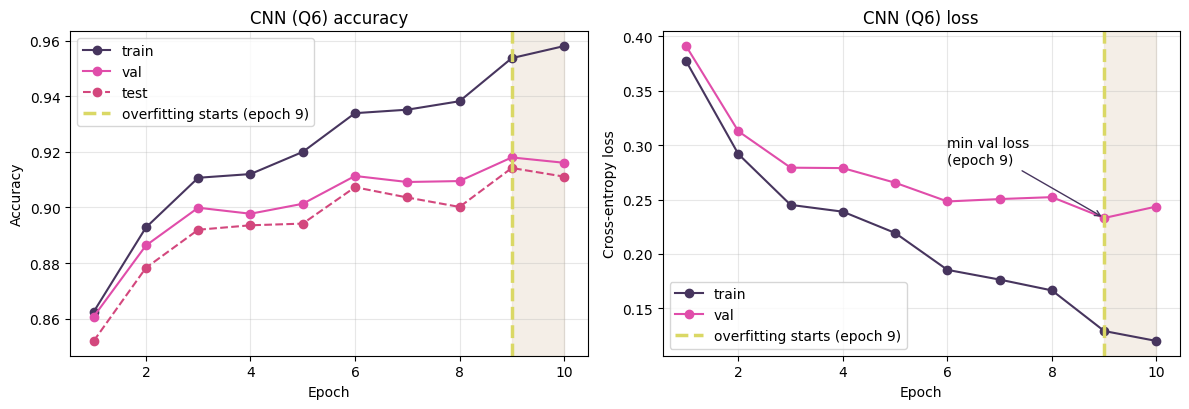

In [121]:
ep = range(1, len(hist_cnn['val_loss']) + 1)
best = int(np.argmin(hist_cnn['val_loss'])) + 1     # epoch with the lowest val loss (+1: epochs start at 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# accuracy
ax = axes[0]
ax.plot(ep, hist_cnn['train_acc'], color='#47355E', marker='o', label='train')
ax.plot(ep, hist_cnn['val_acc'],   color='#E04DAA', marker='o', label='val')
ax.plot(ep, hist_cnn['test_acc'],  color='#D3477D', marker='o', linestyle='--', label='test')
ax.set(title='CNN (Q6) accuracy', xlabel='Epoch', ylabel='Accuracy')

# validation loss
ax = axes[1]
ax.plot(ep, hist_cnn['train_loss'], color='#47355E', marker='o', label='train')
ax.plot(ep, hist_cnn['val_loss'],   color='#E04DAA', marker='o', label='val')
ax.set(title='CNN (Q6) loss', xlabel='Epoch', ylabel='Cross-entropy loss')
ax.annotate(f'min val loss\n(epoch {best})',
            xy=(best, hist_cnn['val_loss'][best - 1]),
            xytext=(best - 3, hist_cnn['val_loss'][best - 1] + 0.05),
            arrowprops=dict(arrowstyle='->', color='#47355E'))

# mark the overfitting point on both plots
for ax in axes:
    ax.axvline(best, color='#DAD865', linewidth=2.5, linestyle='--', label=f'overfitting starts (epoch {best})')
    ax.axvspan(best, max(ep), color='#E5D5C3', alpha=0.4)        # shade the overfitting region
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

*Generate a new CNN with dynamic augmentation - a new tranformed set each 48k generated dataset*

In [122]:
from torch.utils.data import ConcatDataset

norm = transforms.Normalize((float(mean / 255),), (float(std / 255),))   # same stats as before, 0–1 scale

clean_tf = transforms.Compose([transforms.ToTensor(), norm])
aug_tf   = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])

ds_clean = Subset(datasets.FashionMNIST(root='./data', train=True, download=True, transform=clean_tf), train_indices)
ds_aug   = Subset(datasets.FashionMNIST(root='./data', train=True, download=True, transform=aug_tf),   train_indices)

# 48k clean + 48k augmented, with a NEW random augmentation every epoch
train_loader_dyn = DataLoader(ConcatDataset([ds_clean, ds_aug]), batch_size=64, shuffle=True, num_workers=2)

torch.manual_seed(2026)
model_cnn_dyn = ConvNet().to(device)
hist_cnn_dyn = train_model(model_cnn_dyn, train_loader_dyn, val_loader, test_loader, epochs, lr, momentum)

Starting training...
Training batches per epoch: 1500
Validation batches: 188
  Epoch 1, batch 100/1500, loss 1.3073
  Epoch 1, batch 200/1500, loss 0.6781
  Epoch 1, batch 300/1500, loss 0.5785
  Epoch 1, batch 400/1500, loss 0.5184
  Epoch 1, batch 500/1500, loss 0.4811
  Epoch 1, batch 600/1500, loss 0.4278
  Epoch 1, batch 700/1500, loss 0.4369
  Epoch 1, batch 800/1500, loss 0.4371
  Epoch 1, batch 900/1500, loss 0.4179
  Epoch 1, batch 1000/1500, loss 0.4023
  Epoch 1, batch 1100/1500, loss 0.3958
  Epoch 1, batch 1200/1500, loss 0.3874
  Epoch 1, batch 1300/1500, loss 0.3653
  Epoch 1, batch 1400/1500, loss 0.3634
  Epoch 1, batch 1500/1500, loss 0.3265
Epoch 1/10 | train loss 0.3343 acc 0.8784 | val loss 0.3258 acc 0.8823 | test acc 0.8732 | 39.1s
  Epoch 2, batch 100/1500, loss 0.3207
  Epoch 2, batch 200/1500, loss 0.3372
  Epoch 2, batch 300/1500, loss 0.3375
  Epoch 2, batch 400/1500, loss 0.3341
  Epoch 2, batch 500/1500, loss 0.3126
  Epoch 2, batch 600/1500, loss 0.3296


In [123]:
cnn_epochs_dyn= epoch_table(hist_cnn_dyn)
best = cnn_epochs_dyn['val_acc'].idxmax()
print(f'Best validation accuracy at epoch {best} and is {cnn_epochs_dyn['val_acc'].max()*100}%')
cnn_epochs_dyn

Best validation accuracy at epoch 10 and is 92.15%


,train_loss,val_loss,train_acc,val_acc,test_acc,train-val gap,epoch_time
epoch,,,,,,,
1,0.3343,0.3258,0.8784,0.8823,0.8732,-0.0039,39.0808
2,0.2700,0.2682,0.8993,0.9024,0.8959,-0.0032,37.4387
3,0.2396,0.2532,0.9116,0.9100,0.9010,0.0016,38.7015
4,0.2274,0.2521,0.9147,0.9123,0.9039,0.0024,51.8905
5,0.2010,0.2312,0.9260,0.9146,0.9110,0.0114,40.7219
6,0.1832,0.2342,0.9324,0.9190,0.9116,0.0134,38.1811
7,0.1901,0.2527,0.9297,0.9130,0.9094,0.0167,37.4175
8,0.1676,0.2434,0.9381,0.9184,0.9117,0.0197,47.3127
9,0.1493,0.2348,0.9457,0.9188,0.9125,0.0268,41.3123


In [124]:
# Q7: CNN clean (Q6) vs CNN clean + static augmentation vs CNN clean + fresh augmentation each epoch
def summarize(name, hist, n_train):
    best = int(np.argmax(hist['val_acc']))              # epoch index chosen by validation
    return {'model': name,
            'train size': n_train,
            'val acc (final)':  hist['val_acc'][-1],
            'test acc (final)': hist['test_acc'][-1],
            'best val epoch':   best + 1,
            'val acc (best)':   hist['val_acc'][best],
            'test acc (best)':  hist['test_acc'][best],
            'time / epoch (s)': np.mean(hist['epoch_time'][1:])}   # skip epoch 1 warm-up

q7_table = pd.DataFrame([
    summarize('CNN Q6 (clean)',                        hist_cnn,     len(x_train)),
    summarize('CNN Q7 (clean + static aug)',           hist_cnn_aug, len(x_train_augExpand)),
    summarize('CNN Q7 (clean + fresh aug each epoch)', hist_cnn_dyn, len(train_loader_dyn.dataset)),
]).set_index('model').round(4)

q7_table

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
CNN Q6 (clean),48000,0.9161,0.9111,9,0.9180,0.9142,2.0035
CNN Q7 (clean + static aug),96000,0.9172,0.9112,9,0.9196,0.9115,3.8178
CNN Q7 (clean + fresh aug each epoch),96000,0.9215,0.9177,10,0.9215,0.9177,41.4643


Validation accuracy at the best epoch is highest for the CNN Q7 dynamic augmentation model (91.15% at epoch 10), with a corresponding test accuracy of 91.77%. However, all three CNNs are within about 0.5% of each other, so augmentation did not clearly improve accuracy. Fresh augmentation did reduce overfitting: the train-val gap at the best epoch was 0.026, compared with 0.036 (clean) and 0.043 (static).

Static augmentation roughly doubled the time per epoch (2.0 s → 3.8 s) because there's twice as much data. Fresh augmentation was about 20× slower (41.5 s) because every image is re-transformed on the CPU each epoch.